
---
date: "2026-10-11"
date-modified: last-modified
format:
  html:
    toc: true
---



# Diagonalization

**Prerequisites:** [Eigenvalues and Eigenvectors](eigenvalues-and-eigenvectors.ipynb) · [Similar Matrices](change-of-basis-and-similarity.ipynb#def-matrix-similarity)

If a space has a basis made of eigenvectors of an operator, then in that basis the operator does nothing but stretch each axis by its eigenvalue: its matrix is **diagonal**. Such operators are **diagonalizable**. Diagonal matrices are as simple as matrices get; powers, polynomials and long-run behaviour can be read off directly. Not every operator is diagonalizable, and the two multiplicities of an eigenvalue tell exactly when it is.

Throughout, $V$ is a [vector space](vector-spaces.ipynb) of dimension $n$ over a field $K$ and $f : V \to V$ is a linear operator.

## 1\. Diagonalizable Operators

::: {#def-diagonalizable-operator}
## Diagonalizable

1. $f$ is **diagonalizable** if $V$ has a basis consisting of [eigenvectors](eigenvalues-and-eigenvectors.ipynb#def-eigenvalue-eigenvector) of $f$.
2. $A \in M_n(K)$ is **diagonalizable** if it is [similar](change-of-basis-and-similarity.ipynb#def-matrix-similarity) to a diagonal matrix: $P^{-1} A P = D = \operatorname{diag}(\lambda_1, \dots, \lambda_n)$ for some invertible $P$.
:::

::: {#prp-diagonalizable-equivalent}
## Ways to Recognise a Diagonalizable Operator

The following are equivalent:

1. $f$ is diagonalizable;
2. $[f]_{\mathcal{B}}$ is diagonal for some ordered basis $\mathcal{B}$;
3. $V$ is the [direct sum](direct-sums-and-complements.ipynb#def-direct-sum-multiple) of the eigenspaces of $f$;
4. $\sum_\lambda \dim E_\lambda = n$, the sum over the distinct eigenvalues.

For a matrix: $P^{-1} A P = \operatorname{diag}(\lambda_1, \dots, \lambda_n)$ holds exactly when the columns of $P$ are linearly independent eigenvectors of $A$, the $j$-th column having eigenvalue $\lambda_j$.
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-diagonalizable-equivalent
(1 $\iff$ 2) $[f]_{\mathcal{B}}$ is diagonal iff its $j$-th column is $\lambda_j e_j$ for some $\lambda_j$, iff $f(v_j) = \lambda_j v_j$ for each basis vector $v_j$.

(1 $\Rightarrow$ 4) Grouping a basis of eigenvectors by eigenvalue gives, for each $\lambda$, independent vectors in $E_\lambda$, so $\sum_\lambda \dim E_\lambda \ge n$. The sum of the eigenspaces is [direct](eigenvalues-and-eigenvectors.ipynb#cor-direct-sum-eigenspaces), so its dimension $\sum_\lambda \dim E_\lambda$ is at most $n$.

(4 $\Rightarrow$ 3) The direct sum $\bigoplus_\lambda E_\lambda$ is a subspace of dimension $n$ ([dimension of a direct sum](direct-sums-and-complements.ipynb#prp-dim-direct-sum-multiple)), hence [equal to $V$](basis-and-dimension.ipynb#thm-subspace-dimension).

(3 $\Rightarrow$ 1) Putting bases of the eigenspaces together gives a basis of $V$ (same proposition), and it consists of eigenvectors.

For matrices: $AP = PD$ says, column by column, $A P_j = \lambda_j P_j$; and $P$ is invertible iff its columns are independent. $\blacksquare$
:::

::: {#thm-sufficient-diagonalizability}
## $n$ Distinct Eigenvalues Suffice

If $f$ has $n$ pairwise distinct eigenvalues, then $f$ is diagonalizable.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-sufficient-diagonalizability
Choose an eigenvector for each eigenvalue. They are [independent](eigenvalues-and-eigenvectors.ipynb#thm-distinct-eigenvalues-independent), and $n$ independent vectors in an $n$-dimensional space [form a basis](basis-and-dimension.ipynb#cor-independent-full-size). $\blacksquare$
:::

The condition is sufficient, not necessary: the identity matrix has only the eigenvalue $1$ and is diagonal.

### 1\.1\. What a Diagonalizable Operator Does

In an eigenbasis $(v_1, \dots, v_n)$, if $v = \sum c_i v_i$ then $f(v) = \sum c_i \lambda_i v_i$: the operator acts independently on each axis, scaling the $i$-th coordinate by $\lambda_i$. The animation shows $A = \begin{pmatrix} 1 & 1 \\ 0 & 2 \end{pmatrix}$, with eigenvalues $1$ and $2$ and eigenvectors $b_1 = (1, 0)$ and $b_2 = (1, 1)$. The faint grey grid is the fixed standard grid. The coloured grid is built from $b_1$ and $b_2$; under $A$ it stays a grid of the same shape, just stretched by $2$ along the $b_2$-direction. In the coordinates of this grid, $A$ is $\operatorname{diag}(1, 2)$: the yellow vector $v = -0.8\,b_1 + 1.2\,b_2$ goes to $-0.8\,b_1 + 2.4\,b_2$, its $b_1$-coordinate unchanged and its $b_2$-coordinate doubled.


In [1]:

from la_manim import *

class DiagonalInEigenbasis(GridScene):
    def construct(self):
        self.plane.set_stroke(opacity=0.0)          # only the eigen-grid below is moved by A
        b1, b2 = np.array([1.0, 0, 0]), np.array([1.0, 1, 0])
        grid = VGroup(*[Line(k * b2 - 9 * b1, k * b2 + 9 * b1, color=C_BLUE, stroke_width=1.6, stroke_opacity=0.45) for k in range(-6, 7)],
                      *[Line(k * b1 - 6 * b2, k * b1 + 6 * b2, color=C_ORANGE, stroke_width=1.6, stroke_opacity=0.45) for k in range(-12, 13)])
        self.track(grid)
        self.add(grid)
        self.vec(b1, C_BLUE, r"b_1", DOWN)
        self.vec(0.8 * b2, C_ORANGE, r"b_2", RIGHT)
        self.vec([0.4, 1.2], C_YELLOW, r"v", UL)
        cap = VGroup(MathTex(r"A = \begin{pmatrix} 1 & 1 \\ 0 & 2 \end{pmatrix}", color=C_INK),
                     MathTex(r"[A]_{(b_1, b_2)} = \begin{pmatrix} 1 & 0 \\ 0 & 2 \end{pmatrix}", color=C_INK)
                     ).arrange(DOWN, aligned_edge=LEFT).scale(0.7).to_corner(UL, buff=0.3)
        self.play(FadeIn(BackgroundRectangle(cap, fill_opacity=0.85, buff=0.15, color=config.background_color)), FadeIn(cap[0]))
        self.wait(1)
        self.transform([[1, 1], [0, 2]], run_time=4)
        self.play(FadeIn(cap[1]))
        msg = text_caption(r"$v = -0.8\,b_1 + 1.2\,b_2 \ \mapsto\ -0.8\,b_1 + 2.4\,b_2$")
        self.play(FadeIn(msg)); self.wait(2.5)

show(DiagonalInEigenbasis)



::: {.callout-note}
## Diagonalizability Depends on the Field
The rotation $R = \begin{pmatrix} 0 & -1 \\ 1 & 0 \end{pmatrix}$ has characteristic polynomial $\lambda^2 + 1$. Over $\mathbb{R}$ it has no eigenvalues, so it is not diagonalizable: no real line is mapped to itself. Over $\mathbb{C}$ it has the two distinct eigenvalues $\pm i$ and is diagonalizable, with eigenvectors $(1, -i)$ and $(1, i)$.
:::

## 2\. Algebraic and Geometric Multiplicity

::: {#def-multiplicities}
## Multiplicities

Let $\lambda_0$ be an eigenvalue of $f$.

1. Its **algebraic multiplicity** $m_a(\lambda_0)$ is its multiplicity as a root of $p_f$: $p_f(\lambda) = (\lambda - \lambda_0)^{m_a} q(\lambda)$ with $q(\lambda_0) \ne 0$.
2. Its **geometric multiplicity** is $m_g(\lambda_0) = \dim E_{\lambda_0} = \dim \ker(f - \lambda_0\,\mathrm{id})$.
:::

::: {#prp-multiplicity-inequality}
## $1 \le m_g \le m_a$, and the Diagonalizability Criterion

1. For every eigenvalue, $1 \le m_g(\lambda_0) \le m_a(\lambda_0)$.
2. If $p_f$ splits into linear factors over $K$ (for instance if $K$ is algebraically closed), then $f$ is diagonalizable if and only if $m_g(\lambda) = m_a(\lambda)$ for every eigenvalue $\lambda$.
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-multiplicity-inequality
1. $m_g \ge 1$ because $\lambda_0$ has an eigenvector. Let $g = m_g(\lambda_0)$, take a basis $v_1, \dots, v_g$ of $E_{\lambda_0}$ and [extend it](basis-and-dimension.ipynb#thm-extend-to-basis) to a basis $\mathcal{B}$ of $V$. Since $f(v_i) = \lambda_0 v_i$ for $i \le g$,
   $$[f]_{\mathcal{B}} = \begin{pmatrix} \lambda_0 I_g & B \\ 0 & C \end{pmatrix}, \qquad p_f(\lambda) = \det\begin{pmatrix} (\lambda - \lambda_0) I_g & -B \\ 0 & \lambda I - C \end{pmatrix}.$$
   Expanding along the first column $g$ times ([Laplace](laplace-expansion-adjugate-and-cramers-rule.ipynb#thm-laplace-expansion)), each first column having the single entry $\lambda - \lambda_0$, gives $p_f(\lambda) = (\lambda - \lambda_0)^g \det(\lambda I - C)$. Hence $(\lambda - \lambda_0)^g$ divides $p_f$, i.e. $g \le m_a(\lambda_0)$.
2. Since $p_f$ splits and has degree $n$, $\sum_\lambda m_a(\lambda) = n$. By part 1, $\sum_\lambda m_g(\lambda) \le \sum_\lambda m_a(\lambda) = n$, with equality iff $m_g(\lambda) = m_a(\lambda)$ for all $\lambda$. By @prp-diagonalizable-equivalent, $f$ is diagonalizable iff $\sum_\lambda m_g(\lambda) = n$. $\blacksquare$
:::

::: {#exm-defective}
## A Matrix That Is Not Diagonalizable

$J = \begin{pmatrix} \lambda & 1 \\ 0 & \lambda \end{pmatrix}$ has $p_J(t) = (t - \lambda)^2$, so $m_a(\lambda) = 2$. But $J - \lambda I = \begin{pmatrix} 0 & 1 \\ 0 & 0 \end{pmatrix}$ has kernel $\operatorname{span}(e_1)$, so $m_g(\lambda) = 1 < 2$. By the criterion, $J$ is not diagonalizable over any field. Such operators are called **defective**. For $\lambda = 1$ this is the shear studied in the [Triangularization Theorem](triangularization-theorem.ipynb#prp-shear-not-diagonalizable); the [minimal polynomial](minimal-polynomial.ipynb) gives another view of the same phenomenon.
:::

## 3\. Application: Powers and the Fibonacci Numbers

If $A = P D P^{-1}$ with $D$ diagonal, then $A^k = P D^k P^{-1}$, because the inner factors $P^{-1} P$ cancel; and $D^k = \operatorname{diag}(\lambda_1^k, \dots, \lambda_n^k)$. So powers of a diagonalizable matrix, and every quantity defined by a linear recursion, can be written in closed form.

::: {#exm-fibonacci}
## Binet's Formula

The Fibonacci numbers $F_0 = 0$, $F_1 = 1$, $F_{k+1} = F_k + F_{k-1}$ satisfy
$$\begin{pmatrix} F_{k+1} \\ F_k \end{pmatrix} = A \begin{pmatrix} F_k \\ F_{k-1} \end{pmatrix}, \qquad A = \begin{pmatrix} 1 & 1 \\ 1 & 0 \end{pmatrix}, \qquad\text{so}\qquad \begin{pmatrix} F_{k+1} \\ F_k \end{pmatrix} = A^k \begin{pmatrix} 1 \\ 0 \end{pmatrix}.$$
$p_A(\lambda) = \lambda^2 - \lambda - 1$ has the distinct roots $\varphi = \frac{1 + \sqrt5}{2}$ and $\psi = \frac{1 - \sqrt5}{2}$, with eigenvectors $(\varphi, 1)$ and $(\psi, 1)$ (check: $A(\varphi, 1)^{\mathsf T} = (\varphi + 1, \varphi)^{\mathsf T} = \varphi(\varphi, 1)^{\mathsf T}$ since $\varphi^2 = \varphi + 1$). Writing the start vector in the eigenbasis, $(1, 0) = \frac{1}{\sqrt5}\big((\varphi, 1) - (\psi, 1)\big)$, and applying $A^k$ multiplies each eigenvector by $\varphi^k$ resp. $\psi^k$:
$$\begin{pmatrix} F_{k+1} \\ F_k \end{pmatrix} = \frac{1}{\sqrt5}\Big(\varphi^k \begin{pmatrix} \varphi \\ 1 \end{pmatrix} - \psi^k \begin{pmatrix} \psi \\ 1 \end{pmatrix}\Big), \qquad F_k = \frac{\varphi^k - \psi^k}{\sqrt5}.$$
Since $|\psi| < 1$, $F_k$ is the integer nearest to $\varphi^k / \sqrt5$: the eigenvalue $\varphi$ dominates the long-run growth.
:::


eigenvalues: [-0.618034  1.618034]   P^-1 A P =
 [[-0.61803399  0.        ]
 [ 0.          1.61803399]]
Binet == recursion: True   P D^k P^-1 == recursion: True


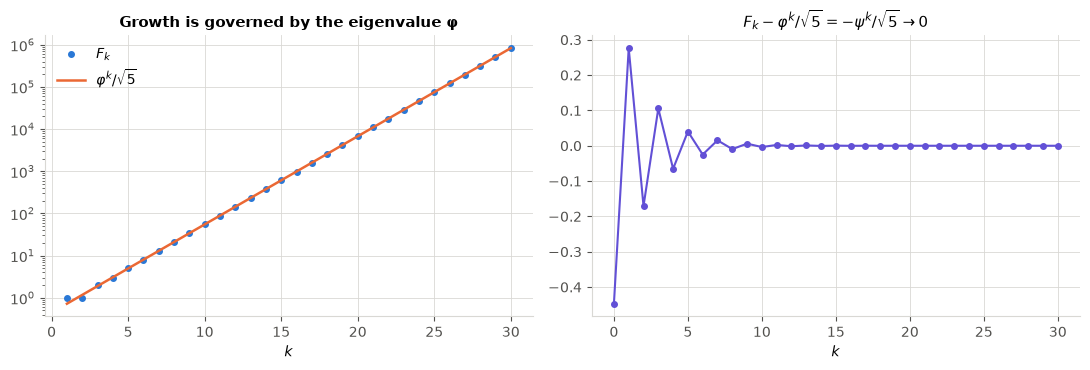

In [2]:

import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, VIOLET = "#2a78d6", "#eb6834", "#6250d6"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update({
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False, "font.size": 10})

A = np.array([[1, 1], [1, 0]], dtype=float)
evals, P = np.linalg.eigh(A)                 # A is symmetric: real eigenvalues
D = np.diag(evals)
print("eigenvalues:", np.round(evals, 6), "  P^-1 A P =\n", np.round(np.linalg.inv(P) @ A @ P, 10))

phi, psi = (1 + 5**0.5) / 2, (1 - 5**0.5) / 2
k = np.arange(0, 31)
fib = [0, 1]
for _ in range(29): fib.append(fib[-1] + fib[-2])
fib = np.array(fib, dtype=float)
binet = (phi**k - psi**k) / 5**0.5
via_powers = np.array([(P @ np.diag(evals**j) @ np.linalg.inv(P) @ [1, 0])[1] for j in k])
print("Binet == recursion:", np.allclose(binet, fib), "  P D^k P^-1 == recursion:", np.allclose(via_powers, fib))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].semilogy(k[1:], fib[1:], "o", color=BLUE, ms=4, label="$F_k$")
axes[0].semilogy(k[1:], phi**k[1:] / 5**0.5, color=ORANGE, lw=1.8, label=r"$\varphi^k/\sqrt{5}$")
axes[0].set_xlabel("$k$"); axes[0].legend(); axes[0].set_title("Growth is governed by the eigenvalue φ")
axes[1].plot(k, fib - phi**k / 5**0.5, "o-", color=VIOLET, ms=4)
axes[1].set_xlabel("$k$"); axes[1].set_title(r"$F_k - \varphi^k/\sqrt{5} = -\psi^k/\sqrt{5} \to 0$")
plt.tight_layout(); plt.show()
